<a href="https://colab.research.google.com/github/MehboobMaitla/HPC_Packed_Binary_Detection/blob/main/HPC_Packed_Binary_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Runtime Event Profiling vs Entropy for Packed Binary Detection
## 1. Setup

In [3]:
!apt-get -qq install -y upx-ucl valgrind strace > /dev/null 2>&1
!pip -q install scikit-learn pandas matplotlib

## 2. Build Dataset (benign, UPX-packed, low-entropy packed)

In [4]:
import os, re, shutil, subprocess, time
import numpy as np, pandas as pd

os.makedirs("bin", exist_ok=True)
names = "ls cat grep sort gzip sed wc head tail cut tr du base64 md5sum sha256sum uniq tee date env id basename dirname".split()

def run_ok(path):
    try:
        return subprocess.run([f"./{path}", "--version"], capture_output=True, timeout=20).returncode
    except Exception:
        return None

samples = []
for n in names:
    src = shutil.which(n)
    if not src: continue
    b, u, l = f"bin/{n}_benign", f"bin/{n}_upx", f"bin/{n}_upxpad"
    shutil.copy(src, b)
    subprocess.run(["upx", "-q", "--best", "-o", u, b], capture_output=True)
    if not os.path.exists(u): continue
    shutil.copy(u, l)
    with open(l, "ab") as f:                      # dilute whole-file entropy with zero padding
        f.write(b"\x00" * (8 * os.path.getsize(u)))
    ref = run_ok(b)
    if ref is None or run_ok(u) != ref or run_ok(l) != ref: continue
    samples += [(b, n, "benign", 0), (u, n, "upx", 1), (l, n, "upx_low_entropy", 1)]

df = pd.DataFrame(samples, columns=["path", "group", "kind", "label"])
df["kind"].value_counts()

,count
kind,
benign,22
upx,22
upx_low_entropy,22


## 3. Entropy Baselines (whole-file and block-wise)
Whole-file entropy is the weak baseline the padding attack targets. Block-wise entropy is a stronger, fairer baseline: padding dilutes the average but not the packed region itself.

In [5]:
def shannon(d):
    p = np.bincount(d, minlength=256); p = p[p > 0] / len(d)
    return float(-(p * np.log2(p)).sum())

def entropy(path):
    return shannon(np.frombuffer(open(path, "rb").read(), dtype=np.uint8))

def block_entropy_stats(path, win=4096, thr=7.0):
    d = np.frombuffer(open(path, "rb").read(), dtype=np.uint8)
    blocks = [d[i:i + win] for i in range(0, len(d) - win + 1, win)] or [d]
    e = np.array([shannon(b) for b in blocks])
    return dict(max_block_entropy=e.max(), frac_high_blocks=float((e > thr).mean()))

df["entropy"] = df.path.map(entropy)
df = pd.concat([df, pd.DataFrame([block_entropy_stats(p) for p in df.path])], axis=1)

df["pred_entropy"] = (df.entropy > 7.0).astype(int)                 # whole-file baseline
df["pred_block_entropy"] = (df.frac_high_blocks >= 0.05).astype(int)  # block-wise baseline (>=5% of 4 KiB blocks above 7.0)
df.groupby("kind")[["entropy", "max_block_entropy", "frac_high_blocks"]].mean().round(3)

,entropy,max_block_entropy,frac_high_blocks
kind,,,
benign,5.308,6.161,0.000
upx,7.816,7.872,1.000
upx_low_entropy,1.342,7.872,0.104


## 4. Runtime Event Profiling

In [6]:
def prof_valgrind(path):
    r = subprocess.run(["valgrind", "--tool=cachegrind", "--branch-sim=yes", "--smc-check=all",
                        "--cachegrind-out-file=cg.out", f"./{path}", "--version"],
                       capture_output=True, text=True, timeout=300)
    keys = [r"I\s+refs", r"D\s+refs", r"D1\s+misses", r"LLd\s+misses", "Branches", "Mispredicts"]
    m = [re.search(rf"{k}\s*:\s*([\d,]+)", r.stderr) for k in keys]
    if not all(m):
        print("valgrind failed on", path, "|", r.stderr.strip().replace("\n", " ")[-200:]); return None
    ins, dr, d1, ll, br, mp = [int(x.group(1).replace(",", "")) for x in m]
    return dict(log_ins=np.log10(ins), br_per_ins=br / ins, mispred_rate=mp / max(br, 1),
                d1_miss_rate=d1 / max(dr, 1), ll_miss_per_kins=ll / ins * 1000)

def prof_strace(path):
    try:
        subprocess.run(["strace", "-f", "-o", "st.txt", f"./{path}", "--version"], capture_output=True, timeout=60)
        L = [l for l in open("st.txt") if "(" in l and "+++" not in l]
    except Exception as e:
        print("strace failed on", path, "|", e); return None
    if not L:
        print("strace produced no trace for", path); return None
    mm = [l for l in L if "mmap(" in l or "mprotect(" in l]
    return dict(log_syscalls=np.log10(len(L)),
                n_rwx=sum("PROT_WRITE" in l and "PROT_EXEC" in l for l in mm),
                n_anon_exec=sum("PROT_EXEC" in l and "MAP_ANONYMOUS" in l for l in mm),
                n_mprotect=sum("mprotect(" in l for l in L),
                n_self_exe=sum("/proc/self/exe" in l for l in L))

HELPER = ("import resource,subprocess,sys;subprocess.run([sys.argv[1],'--version'],capture_output=True);"
          "r=resource.getrusage(resource.RUSAGE_CHILDREN);print(r.ru_minflt,r.ru_maxrss,r.ru_utime+r.ru_stime)")

def prof_soft(path):
    o = subprocess.run(["python3", "-c", HELPER, f"./{path}"], capture_output=True, text=True).stdout.split()
    flt, rss, cpu = map(float, o)
    return dict(log_minflt=np.log10(flt + 1), log_maxrss=np.log10(rss + 1), log_cpu_ms=np.log10(cpu * 1000 + 1))

for backend, fn in [("valgrind cache/branch events", prof_valgrind), ("strace memory-permission events", prof_strace),
                    ("software events (page faults, RSS, CPU)", prof_soft)]:
    t, res = time.time(), []
    for p in df.path:
        r = fn(p)
        if r is None: break
        res.append(r)
    if len(res) == len(df): break
    print("backend unavailable, falling back\n")

print("Backend:", backend)
feature_cols = list(res[0])
df = pd.concat([df, pd.DataFrame(res)], axis=1)
df["prof_s"] = (time.time() - t) / len(df)
df.groupby("kind")[feature_cols].mean().round(4)

valgrind failed on bin/ls_benign |       498,990 ==5444==  ==5444== Branches:       85,984  (83,233 cond + 2,751 ind) ==5444== Mispredicts:     9,406  ( 8,688 cond +   718 ind) ==5444== Mispred rate:     10.9% (  10.4%     +  26.1%   )
backend unavailable, falling back

Backend: strace memory-permission events


,log_syscalls,n_rwx,n_anon_exec,n_mprotect,n_self_exe
kind,,,,,
benign,1.7511,0.0,0.0,3.5,0.0
upx,1.9190,0.0,0.0,8.5,2.0
upx_low_entropy,1.9190,0.0,0.0,8.5,2.0


## 5. HPC-Based Detector (grouped cross-validation)
Variants of the same program stay in the same fold, so the detector is always tested on programs it has never seen.

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict

X = df[feature_cols]
clf = RandomForestClassifier(n_estimators=200, random_state=0)
df["pred_hpc"] = cross_val_predict(clf, X, df.label, groups=df.group, cv=GroupKFold(n_splits=5))

## 6. Comparison

In [8]:
from sklearn.metrics import accuracy_score
detectors = {"entropy, whole file (>7.0)": "pred_entropy",
             "entropy, block-wise": "pred_block_entropy",
             "runtime events + random forest": "pred_hpc"}
cols = list(detectors.values())
res = pd.DataFrame({
    "detection_rate_upx": [df[df.kind == "upx"][c].mean() for c in cols],
    "detection_rate_low_entropy": [df[df.kind == "upx_low_entropy"][c].mean() for c in cols],
    "false_positive_rate": [df[df.kind == "benign"][c].mean() for c in cols],
    "overall_accuracy": [accuracy_score(df.label, df[c]) for c in cols],
}, index=list(detectors))
print(res.round(3))
print(f"\nMean profiling time per binary: {df.prof_s.mean():.2f}s")

                                detection_rate_upx  \
entropy, whole file (>7.0)                     1.0   
entropy, block-wise                            1.0   
runtime events + random forest                 1.0   

                                detection_rate_low_entropy  \
entropy, whole file (>7.0)                             0.0   
entropy, block-wise                                    1.0   
runtime events + random forest                         1.0   

                                false_positive_rate  overall_accuracy  
entropy, whole file (>7.0)                      0.0             0.667  
entropy, block-wise                             0.0             1.000  
runtime events + random forest                  0.0             1.000  

Mean profiling time per binary: 0.03s


## 7. Robustness Checks
Two extra checks: which runtime features carry the signal, and whether the result depends on the entropy threshold or padding size.

In [9]:
# 7a. Feature importance (fit on all data; descriptive only)
imp = pd.Series(RandomForestClassifier(n_estimators=200, random_state=0).fit(X, df.label).feature_importances_,
                index=feature_cols).sort_values(ascending=False)
print("Runtime feature importance:\n", imp.round(3), "\n")

# 7b. Whole-file entropy detection rate across thresholds
for thr in [5.0, 6.0, 7.0]:
    print(f"whole-file entropy > {thr}: low-entropy detection = "
          f"{(df[df.kind == 'upx_low_entropy'].entropy > thr).mean():.2f}, "
          f"false positives = {(df[df.kind == 'benign'].entropy > thr).mean():.2f}")

# 7c. Programs where each detector misses a low-entropy packed sample
low = df[df.kind == "upx_low_entropy"]
for name, c in detectors.items():
    print(f"\nMissed by {name}:", sorted(low[low[c] == 0].group.tolist()) or "none")

Runtime feature importance:
 n_self_exe      0.451
n_mprotect      0.412
log_syscalls    0.137
n_anon_exec     0.000
n_rwx           0.000
dtype: float64 

whole-file entropy > 5.0: low-entropy detection = 0.00, false positives = 0.73
whole-file entropy > 6.0: low-entropy detection = 0.00, false positives = 0.00
whole-file entropy > 7.0: low-entropy detection = 0.00, false positives = 0.00

Missed by entropy, whole file (>7.0): ['base64', 'basename', 'cat', 'cut', 'date', 'dirname', 'du', 'env', 'grep', 'gzip', 'head', 'id', 'ls', 'md5sum', 'sed', 'sha256sum', 'sort', 'tail', 'tee', 'tr', 'uniq', 'wc']

Missed by entropy, block-wise: none

Missed by runtime events + random forest: none


## 8. Visualization

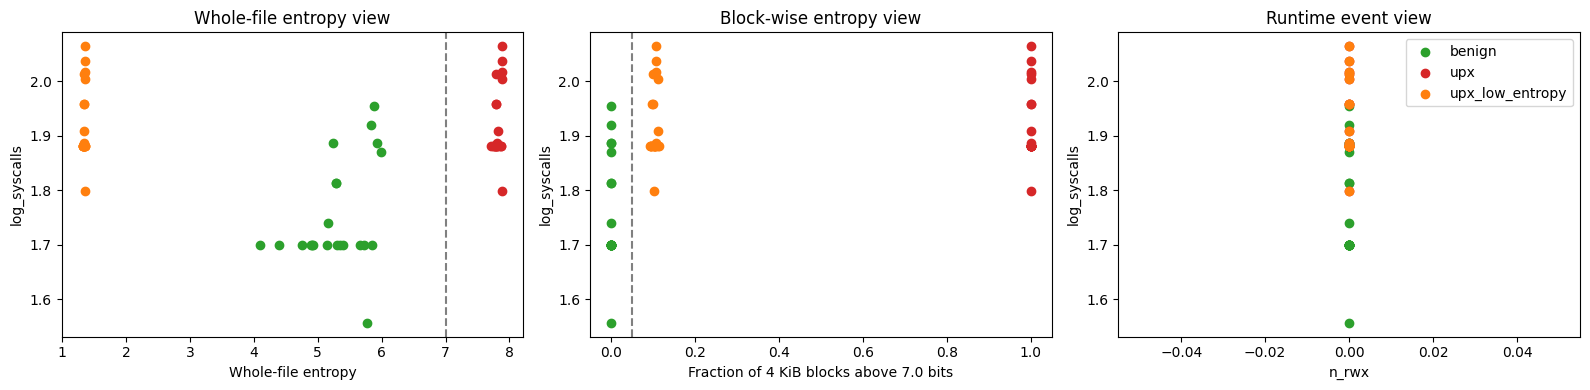

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
col = {"benign": "tab:green", "upx": "tab:red", "upx_low_entropy": "tab:orange"}
fx, fy = feature_cols[1], feature_cols[0]
for k, g in df.groupby("kind"):
    ax[0].scatter(g.entropy, g[fy], c=col[k], label=k)
    ax[1].scatter(g.frac_high_blocks, g[fy], c=col[k], label=k)
    ax[2].scatter(g[fx], g[fy], c=col[k], label=k)
ax[0].axvline(7.0, ls="--", c="gray"); ax[0].set(xlabel="Whole-file entropy", ylabel=fy, title="Whole-file entropy view")
ax[1].axvline(0.05, ls="--", c="gray"); ax[1].set(xlabel="Fraction of 4 KiB blocks above 7.0 bits", ylabel=fy, title="Block-wise entropy view")
ax[2].set(xlabel=fx, ylabel=fy, title="Runtime event view"); ax[2].legend()
plt.tight_layout(); plt.show()